# Epithelial reintegration, specimen origin and CNV sensitivity

## Setup

In [1]:
import gc
import hashlib
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

import scanpy as sc
import anndata as ad
import infercnvpy as cnv
import scvi

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

import rpy2.robjects as ro
import rpy2.rinterface_lib.callbacks as rcb
import logging


/opt/miniconda3/envs/cap/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Error importing in API mode: ImportError("dlopen(/opt/miniconda3/envs/cap/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib\n  Referenced from: <1984CB9B-890E-3855-A246-270AC6AC4C62> /opt/miniconda3/envs/cap/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file)")
Trying t

In [2]:
np.random.seed(0)
scvi.settings.seed = 0
scvi.settings.num_workers = 4

sc.settings.verbosity = 2
rcb.logger.setLevel(logging.ERROR)


Seed set to 0


In [3]:
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")

plt.rcParams.update({
    "font.size": 20,
    "axes.titlesize": 20,
    "axes.labelsize": 16,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 300,
})


In [4]:
target_genes = ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]


In [ ]:
random_seed = 0
n_hvg_primary = 4000
cnv_high_quantile = 0.95
infercnv_dynamic_threshold = 1.5 #package default
cnv_quantiles = (0.90, 0.95, 0.99)


In [6]:
n_latent = 20
n_layers = 2
gene_likelihood = "nb"
n_neighbors = 30
primary_resolution = 0.5
leiden_resolutions = (0.5, 1.0, 1.2, 1.5)


In [ ]:
def find_project(start=None):
    here = Path(start or Path.cwd()).resolve()
    for parent in [here, *here.parents]:
        if (parent / "Data").is_dir() and (parent / "metadata").is_dir():
            return parent
    raise FileNotFoundError("Set CAP_PROJECT to the project data directory")


def find_publication():
    here = Path.cwd().resolve()
    for parent in [here, *here.parents]:
        for candidate in (parent, parent / "publication_notebooks"):
            if (candidate / "scripts" / "publication_figure_state.py").is_file():
                if (candidate / "data" / "cancer_meta_programme_signatures.xlsx").is_file():
                    return candidate
    raise FileNotFoundError("Run from the publication_notebooks directory")


In [8]:
project = Path(os.environ.get("CAP_PROJECT") or find_project()).expanduser().resolve()

data_dir = project / "Data"
fig_dir = project / "Figures"
df_dir = project / "Dataframe_Saves"
save_dir = project / "Adata_Saves"
model_dir = project / "scvi_epithelial_model"
notebook_dir = find_publication()


In [9]:
for d in [fig_dir, df_dir, save_dir, model_dir]:
    d.mkdir(parents=True, exist_ok=True)


In [ ]:
sc.settings.figdir = fig_dir

meta_programme_file = notebook_dir / "data" / "cancer_meta_programme_signatures.xlsx"
gencode_file = data_dir / "gencode.v50.annotation.gtf.gz"
source_tumour_file = (
    notebook_dir / "data"
    / "source_tumour_cluster_barcodes.csv.gz"
)


In [11]:
for path in [meta_programme_file, gencode_file, source_tumour_file]:
    assert path.exists(), path


In [ ]:
source_tumour_sha256 = ("26af400ae38a5e878873c1cb30e83b8447440518a8727fdf7a8808d7780ede5c")
actual_source_tumour_sha256 = hashlib.sha256(
    source_tumour_file.read_bytes()
).hexdigest()
assert actual_source_tumour_sha256 == source_tumour_sha256


In [13]:
def rel(path):
    return Path(path).relative_to(project)


## Load the epithelial compartment

In [14]:
epi = sc.read_h5ad(save_dir / "epithelial.h5ad")


legacy_celltypist_columns = {
    "celltypist_pal_label": "celltypist_reference_label",
    "celltypist_pal_conf": "celltypist_reference_confidence",
}


In [15]:
epi.obs.rename(
    columns={
        old: new for old, new in legacy_celltypist_columns.items()
        if old in epi.obs.columns and new not in epi.obs.columns
    },
    inplace=True,
)


In [16]:
display(pd.DataFrame({
    "cells": [epi.n_obs],
    "genes": [epi.n_vars],
    "samples": [epi.obs["sample"].nunique()],
}))


,cells,genes,samples
0,129599,28552,45


In [17]:
# Keep the atlas coordinates from 002 before calculating the epithelial embedding.
if "X_umap" in epi.obsm and "X_umap_atlas" not in epi.obsm:
    epi.obsm["X_umap_atlas"] = epi.obsm["X_umap"].copy()


In [18]:
counts = epi.layers["counts"]
count_values = counts.data if sp.issparse(counts) else np.asarray(counts).ravel()

assert np.isfinite(count_values).all()
assert np.allclose(count_values, np.rint(count_values))

baseline_positive = {
    gene: int((np.asarray(epi[:, gene].layers["counts"].todense()).ravel() > 0).sum())
    for gene in target_genes
}
display(pd.Series(baseline_positive, name="cells_with_raw_count"))


ROR1      1171
ROR2      2689
EGFR     13076
ERBB2    36641
EPCAM    62303
Name: cells_with_raw_count, dtype: int64

## Gene filtering and normalisation

In [19]:
n_cells_loaded = epi.n_obs
n_genes_loaded = epi.n_vars


In [20]:
sc.pp.filter_genes(epi, min_cells=3)
n_genes_removed = n_genes_loaded - epi.n_vars


filtered out 1195 genes that are detected in less than 3 cells


In [21]:
n_cells_start = epi.n_obs
n_genes_start = epi.n_vars


In [22]:
shape_summary = pd.DataFrame({
    "stage": ["loaded", "analysis object"],
    "cells": [n_cells_loaded, epi.n_obs],
    "genes": [n_genes_loaded, epi.n_vars],
})
display(shape_summary)


,stage,cells,genes
0,loaded,129599,28552
1,analysis object,129599,27357


In [23]:
epi.layers["lognorm"] = epi.layers["log1p"].copy()
epi.X = epi.layers["lognorm"].copy()


In [24]:
# the master shape that must survive inferCNV, scVI and clustering unchanged
n_cells_start = epi.n_obs
n_genes_start = epi.n_vars

assert n_cells_start == n_cells_loaded
assert n_genes_start == n_genes_loaded - n_genes_removed


## Highly variable genes



Binomial deviance (`scry`) computed per sample and aggregated by the maximum
across samples, so that a gene deviant in a single condition is retained.
Mitochondrial, ribosomal and haemoglobin genes are excluded before ranking.
Cell-cycle genes are deliberately **not** excluded here: proliferation is a
tumour-associated epithelial state of interest.

In [25]:
%load_ext rpy2.ipython


In [26]:
%%R
suppressPackageStartupMessages({
    library(Matrix)
    library(SingleCellExperiment)
    library(scry)
})


In [27]:
def scipy_to_dgc(matrix):
    # transfer a scipy sparse matrix to R as a dgCMatrix
    matrix = sp.csc_matrix(matrix)
    return ro.r["new"](
        "dgCMatrix",
        i=ro.IntVector(matrix.indices),
        p=ro.IntVector(matrix.indptr),
        x=ro.FloatVector(matrix.data),
        Dim=ro.IntVector(matrix.shape),
    )


In [28]:
samples = epi.obs["sample"].astype(str).unique().tolist()

deviance = pd.DataFrame(index=epi.var_names, columns=samples, dtype=float)


In [29]:
for sample in samples:

    sub = epi[epi.obs["sample"].astype(str) == sample]

    ro.globalenv["raw_counts"] = scipy_to_dgc(sub.layers["counts"].T)
    ro.globalenv["gene_names"] = ro.StrVector(sub.var_names.tolist())
    ro.globalenv["cell_names"] = ro.StrVector(sub.obs_names.tolist())

    ro.r('''
        rownames(raw_counts) <- gene_names
        colnames(raw_counts) <- cell_names

        sce <- SingleCellExperiment(assays = list(counts = raw_counts))
        sce <- devianceFeatureSelection(sce)

        binomial_deviance <- rowData(sce)$binomial_deviance
    ''')

    deviance[sample] = np.asarray(ro.r["binomial_deviance"])

    ro.r("rm(raw_counts, sce, binomial_deviance); gc()")

    print(f"{sample}: {sub.n_obs:,} cells")


GSM4909295_ER-AH0319: 567 cells
GSM4909296_ER-MH0001: 5,059 cells
GSM4909302_ER-MH0025: 3,713 cells
GSM4909305_ER-MH0029-7C: 2,037 cells
GSM4909306_ER-MH0029-9C: 5,841 cells
GSM4909300_ER-MH0032: 495 cells
GSM4909307_ER-MH0040: 4,989 cells
GSM4909301_ER-MH0042: 2,704 cells
GSM4909309_ER-MH0043-T: 2,582 cells
GSM4909311_ER-MH0056-T: 2,901 cells
GSM4909313_ER-MH0064-T: 2,944 cells
GSM4909299_ER-MH0114-T3: 5,777 cells
GSM4909297_ER-MH0125: 5,408 cells
GSM4909303_ER-MH0151: 712 cells
GSM4909304_ER-MH0163: 5,074 cells
GSM4909315_ER-MH0167-T: 4,824 cells
GSM4909317_ER-MH0173-T: 2,608 cells
GSM4909298_ER-PM0360: 1,825 cells
GSM4909289_HER2-AH0308: 3,029 cells
GSM4909291_HER2-MH0031: 1,453 cells
GSM4909292_HER2-MH0069: 239 cells
GSM4909293_HER2-MH0161: 3,854 cells
GSM4909294_HER2-MH0176: 4,979 cells
GSM4909290_HER2-PM0337: 2,943 cells
GSM4909272_N-MH0021-Total: 1,228 cells
GSM4909268_N-MH0023-Total: 4,055 cells
GSM4909263_N-MH0064-Total: 716 cells
GSM4909266_N-MH0169-Total: 717 cells
GSM490927

In [30]:
epi.var["binomial_deviance"] = deviance.max(axis=1)

assert epi.var["binomial_deviance"].notna().all()


In [31]:
for column in ["mt", "ribo", "hb"]:
    assert column in epi.var.columns, column

exclude = epi.var[["mt", "ribo", "hb"]].any(axis=1)


In [32]:
ranked = (
    epi.var.loc[~exclude, "binomial_deviance"]
    .sort_values(ascending=False)
    .index
)

deviant_genes = ranked[:n_hvg_primary]


In [33]:
# These genes are tracked for a sensitivity model, but do not enter the primary model unless selected by deviance.
meta_programme_sheet = pd.read_excel(meta_programme_file, sheet_name="Cancer MPs")
meta_programme_genes = (
    meta_programme_sheet.stack().dropna().astype(str).str.strip().loc[lambda x: x.ne("")].unique()
)


In [34]:
protected = sorted(set(target_genes) | set(meta_programme_genes))
protected_present = [gene for gene in protected if gene in epi.var_names]


In [35]:
epi.var["highly_variable_deviance"] = epi.var_names.isin(deviant_genes)
epi.var["highly_variable_protected"] = (
    epi.var["highly_variable_deviance"] | epi.var_names.isin(protected_present)
)

# The primary embedding is independent of the antigen and meta-programme lists.
epi.var["highly_variable"] = epi.var["highly_variable_deviance"].copy()

n_hvg_deviance = int(epi.var["highly_variable_deviance"].sum())
n_hvg_protected = int(epi.var["highly_variable_protected"].sum())
n_protected_added = n_hvg_protected - n_hvg_deviance


In [36]:
hvg_summary = pd.DataFrame({
    "feature_set": ["primary_deviance", "protected_sensitivity"],
    "n_genes": [n_hvg_deviance, n_hvg_protected],
})
display(hvg_summary)

pd.Series(deviant_genes, name="gene").to_csv(
    df_dir / "epithelial_hvg_genes.csv", index=False
)


,feature_set,n_genes
0,primary_deviance,4000
1,protected_sensitivity,4588


## inferCNV


Run inferCNV on a separate object so its gene filtering cannot alter the integration object. Genomic coordinates come from GENCODE v50 and are joined by stable Ensembl gene ID. The primary run uses infercnvpy's documented default dynamic threshold of 1.5. The normal-reference quantile sensitivity below does not test this smoothing parameter.

In [37]:
# inferCNV needs log-normalised expression, the sample annotation and the gene coordinates. A full epi.copy() would also carry the counts layer and double peak memory for no benefit, so the working object is built slim.
cnv_adata = ad.AnnData(
    X=epi.layers["lognorm"].copy(),
    obs=epi.obs.copy(),
    var=epi.var.copy(),
)

print(f"inferCNV working object: {cnv_adata.n_obs:,} cells x {cnv_adata.n_vars:,} genes")


inferCNV working object: 129,599 cells x 27,357 genes


In [38]:
gtf = pd.read_csv(
    gencode_file,
    sep="\t",
    comment="#",
    header=None,
    names=["chromosome", "source", "feature", "start", "end",
           "score", "strand", "frame", "attribute"],
)


In [39]:
gencode = gtf[gtf["feature"] == "gene"].copy()


In [40]:
gencode["ensembl"] = (
    gencode["attribute"].str.extract(r'gene_id "([^"]+)"')[0].str.split(".").str[0]
)


In [41]:
gencode["gene_type"] = gencode["attribute"].str.extract(r'gene_type "([^"]+)"')[0]


In [42]:
gencode = gencode.drop_duplicates("ensembl").set_index("ensembl")


In [43]:
len(gencode)


78733

In [44]:
del gtf
gc.collect()


43

In [45]:
# join on stable Ensembl identifiers taken from the dataset's own annotation
ensembl = cnv_adata.var["gene_id"].astype(str).str.split(".").str[0]


In [46]:
cnv_adata.var["chromosome"] = ensembl.map(gencode["chromosome"]).values
cnv_adata.var["start"] = ensembl.map(gencode["start"]).values
cnv_adata.var["end"] = ensembl.map(gencode["end"]).values
cnv_adata.var["gene_type"] = ensembl.map(gencode["gene_type"]).values

resolved = cnv_adata.var["chromosome"].notna()


In [47]:
del gencode
gc.collect()


28

In [48]:
resolved.sum(), cnv_adata.n_vars


(np.int64(26534), 27357)

In [49]:
cnv_adata.var.loc[~resolved, ["gene_id"]].to_csv(df_dir / "infercnv_unresolved_genes.csv")


In [50]:
# protein-coding autosomal genes only


In [51]:
autosomes = [f"chr{i}" for i in range(1, 23)]

keep = (
    cnv_adata.var["chromosome"].isin(autosomes)
    & cnv_adata.var["gene_type"].eq("protein_coding")
)


In [52]:
cnv_adata = cnv_adata[:, keep].copy()


In [53]:
cnv_adata.n_vars


17495

In [54]:
# gene families whose variation is not driven by copy number
problematic = (
    cnv_adata.var_names.str.startswith(
        ("MT-", "RPS", "RPL", "HLA-", "IGH", "IGK", "IGL", "KRT", "SPRR", "S100A")
    )
    | cnv_adata.var_names.isin(["MALAT1", "NEAT1"])
)


In [55]:
problematic.sum()


np.int64(230)

In [56]:
cnv_adata = cnv_adata[:, ~problematic].copy()


In [57]:
sc.pp.filter_genes(cnv_adata, min_cells=100)


filtered out 2366 genes that are detected in less than 100 cells


In [58]:
cnv_adata.n_vars


14899

In [59]:
# genomic ordering
cnv_adata.var["chromosome"] = cnv_adata.var["chromosome"].astype(str)
cnv_adata.var["chr_num"] = cnv_adata.var["chromosome"].str.replace("chr", "", regex=False).astype(int)

order = cnv_adata.var.sort_values(["chr_num", "start"]).index
cnv_adata = cnv_adata[:, order].copy()

assert cnv_adata.var_names.is_unique
assert (np.diff(cnv_adata.var["chr_num"].to_numpy()) >= 0).all()


In [60]:
# normal epithelium provides the diploid reference
reference = cnv_adata[cnv_adata.obs["condition"] == "N"].copy()

print(f"reference cells: {reference.n_obs:,} from {reference.obs['sample'].nunique()} samples")


reference cells: 26,425 from 13 samples


In [61]:
cnv_adata.obs["cnv_score"] = np.nan
cnv_adata.obs["cnv_signal"] = np.nan

x_cnv_full = None
failures = []

cnv_samples = cnv_adata.obs["sample"].astype(str).unique().tolist()


In [62]:
len(cnv_samples)


45

In [63]:
for sample in cnv_samples:

    print(f"\n{sample}")

    target = refs = combined = None

    try:
        target = cnv_adata[cnv_adata.obs["sample"].astype(str) == sample].copy()
        condition = str(target.obs["condition"].iloc[0])

        # a normal sample is never its own reference
        if condition == "N":
            refs = reference[reference.obs["sample"].astype(str) != sample].copy()
        else:
            refs = reference.copy()

        assert refs.n_obs > 0

        refs.obs["cnv_reference"] = "reference"
        target.obs["cnv_reference"] = "query"

        combined = sc.concat([refs, target], join="inner", merge="same")

        print(f"  {condition}: {target.n_obs:,} query, {refs.n_obs:,} reference")

        # X holds log-normalised expression, so no layer is passed
        cnv.tl.infercnv(
            combined,
            reference_key="cnv_reference",
            reference_cat=["reference"],
            window_size=100,
            step=10,
            dynamic_threshold=infercnv_dynamic_threshold,
            exclude_chromosomes=("chrX", "chrY"),
            n_jobs=1,
        )

        x_cnv = combined.obsm["X_cnv"]
        x_cnv = x_cnv.toarray() if sp.issparse(x_cnv) else np.asarray(x_cnv)
        x_cnv = x_cnv.astype(np.float32)

        query = combined.obs["cnv_reference"].eq("query").to_numpy()
        query_names = combined.obs_names[query]
        x_query = x_cnv[query]

        # map each inferCNV window to its chromosome
        chr_pos = sorted(combined.uns["cnv"]["chr_pos"].items(), key=lambda kv: kv[1])
        n_windows = x_query.shape[1]

        chr_labels = np.empty(n_windows, dtype=object)

        for i, (chrom, start) in enumerate(chr_pos):
            end = chr_pos[i + 1][1] if i + 1 < len(chr_pos) else n_windows
            chr_labels[start:end] = chrom

        # Chromosome RMS burden weighted by window count; chromosomes with more windows receive more weight.
        chrom_scores = []
        chrom_weights = []

        for chrom in pd.unique(chr_labels):
            idx = np.flatnonzero(chr_labels == chrom)
            chrom_scores.append(np.sqrt(np.mean(x_query[:, idx] ** 2, axis=1)))
            chrom_weights.append(len(idx))

        chrom_scores = np.column_stack(chrom_scores)
        chrom_weights = np.asarray(chrom_weights, dtype=float)
        chrom_weights /= chrom_weights.sum()

        cnv_score = np.average(chrom_scores, axis=1, weights=chrom_weights)
        cnv_signal = np.max(np.abs(x_query), axis=1)

        cnv_adata.obs.loc[query_names, "cnv_score"] = cnv_score
        cnv_adata.obs.loc[query_names, "cnv_signal"] = cnv_signal

        if x_cnv_full is None:
            x_cnv_full = np.full((cnv_adata.n_obs, n_windows), np.nan, dtype=np.float32)

        if "cnv" not in cnv_adata.uns:
            cnv_adata.uns["cnv"] = dict(combined.uns["cnv"])

        x_cnv_full[cnv_adata.obs_names.get_indexer(query_names)] = x_query

        print(f"  median burden {np.median(cnv_score):.4f}")

    except Exception as error:
        print(f"  failed: {error}")
        failures.append({"sample": sample, "error": str(error)})

    finally:
        del target, refs, combined
        gc.collect()



GSM4909295_ER-AH0319
  ER+: 567 query, 26,425 reference


100%|██████████| 6/6 [00:09<00:00,  1.54s/it]


  median burden 0.0441

GSM4909296_ER-MH0001
  ER+: 5,059 query, 26,425 reference


100%|██████████| 7/7 [00:10<00:00,  1.48s/it]


  median burden 0.0330

GSM4909302_ER-MH0025
  ER+: 3,713 query, 26,425 reference


...

  median burden 0.0367

GSM4909283_TN-SH0106
  TN: 54 query, 26,425 reference


100%|██████████| 6/6 [00:09<00:00,  1.66s/it]


  median burden 0.0312

GSM4909287_TN-B1-Tum0554
  TN: 2,684 query, 26,425 reference


100%|██████████| 6/6 [00:10<00:00,  1.82s/it]


  median burden 0.0393


In [64]:
# Missing inferCNV results must never pass silently into downstream calls.
failures = pd.DataFrame(failures)

if not failures.empty:
    failures.to_csv(df_dir / "infercnv_failed_samples.csv", index=False)
    raise RuntimeError(f"inferCNV failed for {len(failures)} sample(s)")

assert cnv_adata.obs[["cnv_score", "cnv_signal"]].notna().all().all()

display(pd.DataFrame({"infercnv_samples_completed": [len(cnv_samples)]}))


,infercnv_samples_completed
0,45


In [65]:
valid = cnv_adata.obs[["cnv_score", "total_counts"]].dropna()
r = np.corrcoef(valid["cnv_score"], valid["total_counts"])[0, 1]
display(pd.DataFrame({"cnv_score_vs_total_counts_r": [r]}).round(3))


,cnv_score_vs_total_counts_r
0,-0.241


In [66]:
cnv_adata.obs.groupby("condition", observed=True)["cnv_score"].describe().round(4)


,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
N,26425.0,0.0259,0.0102,0.0005,0.0182,0.0271,0.0334,0.0658
TN,26617.0,0.0380,0.0096,0.0010,0.0316,0.0382,0.0445,0.1652
HER2+,16497.0,0.0367,0.0083,0.0041,0.0315,0.0364,0.0416,0.1023
ER+,60060.0,0.0355,0.0073,0.0015,0.0311,0.0354,0.0399,0.0898


## Specimen origin and CNV-high sensitivity



The primary population definition follows specimen origin. Epithelial cells
from ER+, HER2+ and TN specimens are labelled `tumour_derived`; this does not
imply that every cell is malignant. Normal-tissue epithelial cells provide the
reference population.

`cnv_high` is a technical flag applied to every epithelial cell whose inferred
CNV burden exceeds the 95th percentile of normal epithelium. The conjunction
of tumour origin and this flag is stored as `tumour_derived_cnv_high`. This is a
conservative CNV-enriched subgroup, not a classification of every tumour-derived cell.

Released tumour-cluster barcodes are retained only as an external concordance
variable. G1-restricted summaries assess whether cell-cycle transcription
materially affects the CNV-high sensitivity analysis.


In [67]:
condition_values = cnv_adata.obs["condition"].astype(str)
phase_values = cnv_adata.obs["phase"].astype(str)

normal_mask = condition_values.eq("N")
normal_scores = cnv_adata.obs.loc[normal_mask, "cnv_score"]
normal_g1_scores = cnv_adata.obs.loc[
    normal_mask & phase_values.eq("G1"), "cnv_score"
]

cnv_high_threshold = float(normal_scores.quantile(cnv_high_quantile))
cnv_high_threshold_g1 = float(normal_g1_scores.quantile(cnv_high_quantile))

source_tumour = pd.read_csv(
    source_tumour_file,
    dtype={"sample_code": str, "barcode": str},
)
required_columns = {"condition", "sample_code", "barcode", "source_cluster"}
assert required_columns.issubset(source_tumour.columns)


In [68]:
assert not source_tumour.duplicated(
    ["condition", "sample_code", "barcode"]
).any()


In [69]:
def sample_code(sample):
    sample_name = str(sample).split("_", 1)[-1]
    matches = re.findall(r"(?<!\d)(\d{4})(?!\d)", sample_name)
    return matches[-1] if matches else ""


In [70]:
condition_values = cnv_adata.obs["condition"].astype(str)
sample_codes = cnv_adata.obs["sample"].astype(str).map(sample_code)
cell_barcodes = cnv_adata.obs_names.to_series().str.split("-GSM").str[0]

source_keys = set(source_tumour[
    ["condition", "sample_code", "barcode"]
].itertuples(index=False, name=None))
available_groups = set(source_tumour[
    ["condition", "sample_code"]
].drop_duplicates().itertuples(index=False, name=None))

cell_keys = zip(condition_values, sample_codes, cell_barcodes)


In [ ]:
sample_keys = zip(condition_values, sample_codes)

cnv_adata.obs["source_tumour_cluster"] = np.fromiter(
    (key in source_keys for key in cell_keys), dtype=bool, count=cnv_adata.n_obs
)
cnv_adata.obs["source_tumour_cluster_eligible"] = np.fromiter(
    (key in available_groups for key in sample_keys),
    dtype=bool,
    count=cnv_adata.n_obs,
)

# Source sample identity must be supported before any barcode transfer.
transfer_exclusions = pd.read_csv(
    notebook_dir / "data" / "source_transfer_exclusions.csv"
)
not_transferable = cnv_adata.obs["sample"].astype(str).isin(transfer_exclusions["sample"])
cnv_adata.obs.loc[not_transferable, "source_tumour_cluster"] = False
cnv_adata.obs.loc[not_transferable, "source_tumour_cluster_eligible"] = False


In [72]:
cnv_adata.obs["tumour_derived"] = condition_values.ne("N")
cnv_adata.obs["cnv_high"] = cnv_adata.obs["cnv_score"].gt(
    cnv_high_threshold
)
cnv_adata.obs["tumour_derived_cnv_high"] = (
    cnv_adata.obs["tumour_derived"] & cnv_adata.obs["cnv_high"]
)
cnv_adata.obs["g1_cell"] = phase_values.eq("G1")
cnv_adata.obs["tumour_derived_cnv_high_g1"] = (
    cnv_adata.obs["tumour_derived_cnv_high"] & cnv_adata.obs["g1_cell"]
)


In [73]:
origin_call = np.where(
    condition_values.eq("N"),
    "normal-tissue epithelium",
    "tumour-derived epithelium",
)
origin_order = ["normal-tissue epithelium", "tumour-derived epithelium"]

source_call = np.full(cnv_adata.n_obs, "not evaluated", dtype=object)
normal = condition_values.eq("N").to_numpy()
eligible = cnv_adata.obs["source_tumour_cluster_eligible"].to_numpy()
source_tumour_mask = cnv_adata.obs["source_tumour_cluster"].to_numpy()

source_call[normal] = "normal reference"
source_call[eligible] = "other epithelial"
source_call[source_tumour_mask] = "source tumour cluster"
source_call_order = [
    "normal reference", "source tumour cluster", "other epithelial",
    "not evaluated",
]


In [74]:
cnv_adata.obs["specimen_origin"] = pd.Categorical(
    origin_call, categories=origin_order
)
cnv_adata.obs["source_tumour_cluster_call"] = pd.Categorical(
    source_call, categories=source_call_order
)

population_counts = pd.crosstab(
    cnv_adata.obs["condition"], cnv_adata.obs["specimen_origin"], margins=True
)


In [75]:
display(population_counts)


specimen_origin,normal-tissue epithelium,tumour-derived epithelium,All
condition,,,
N,26425,0,26425
TN,0,26617,26617
HER2+,0,16497,16497
ER+,0,60060,60060
All,26425,103174,129599


In [76]:
rows = []


In [77]:
for quantile in cnv_quantiles:
    threshold = float(normal_scores.quantile(quantile))
    called = (
        cnv_adata.obs["cnv_score"].gt(threshold)
        & cnv_adata.obs["condition"].ne("N")
    )

    for condition in ["ER+", "HER2+", "TN"]:
        mask = cnv_adata.obs["condition"].eq(condition)
        rows.append({
            "normal_quantile": quantile,
            "threshold": threshold,
            "condition": condition,
            "n_cells": int(mask.sum()),
            "n_cnv_high": int(called[mask].sum()),
            "cnv_high_fraction": float(called[mask].mean()),
        })


In [78]:
threshold_sensitivity = pd.DataFrame(rows)
threshold_sensitivity.to_csv(
    df_dir / "infercnv_threshold_sensitivity.csv", index=False
)
display(threshold_sensitivity.round(4))


,normal_quantile,threshold,condition,n_cells,n_cnv_high,cnv_high_fraction
0,0.90,0.0381,ER+,60060,20472,0.3409
1,0.90,0.0381,HER2+,16497,6801,0.4123
2,0.90,0.0381,TN,26617,13416,0.5040
3,0.95,0.0411,ER+,60060,11873,0.1977
4,0.95,0.0411,HER2+,16497,4463,0.2705
5,0.95,0.0411,TN,26617,10021,0.3765
6,0.99,0.0474,ER+,60060,2861,0.0476
7,0.99,0.0474,HER2+,16497,1534,0.0930
8,0.99,0.0474,TN,26617,4321,0.1623


In [79]:
cycle_cnv_summary = (
    cnv_adata.obs
    .groupby(["condition", "phase"], observed=True)
    .agg(
        n_cells=("cnv_score", "size"),
        median_cnv=("cnv_score", "median"),
        cnv_high_fraction=("cnv_high", "mean"),
        tumour_derived_cnv_high_fraction=("tumour_derived_cnv_high", "mean"),
    )
    .reset_index()
)
cycle_cnv_summary["normal_all_q95"] = cnv_high_threshold
cycle_cnv_summary["normal_g1_q95"] = cnv_high_threshold_g1
cycle_cnv_summary.to_csv(
    df_dir / "infercnv_cell_cycle_sensitivity.csv", index=False
)
display(cycle_cnv_summary.round(4))


,condition,phase,n_cells,median_cnv,cnv_high_fraction,tumour_derived_cnv_high_fraction,normal_all_q95,normal_g1_q95
0,N,G1,20101,0.0255,0.0412,0.0000,0.0411,0.0402
1,N,G2M,3592,0.0308,0.0735,0.0000,0.0411,0.0402
2,N,S,2732,0.0315,0.0838,0.0000,0.0411,0.0402
3,TN,G1,13586,0.0347,0.2406,0.2406,0.0411,0.0402
4,TN,G2M,6185,0.0430,0.5874,0.5874,0.0411,0.0402
5,TN,S,6846,0.0402,0.4556,0.4556,0.0411,0.0402
6,HER2+,G1,12301,0.0360,0.2538,0.2538,0.0411,0.0402
7,HER2+,G2M,1436,0.0380,0.3370,0.3370,0.0411,0.0402
8,HER2+,S,2760,0.0374,0.3105,0.3105,0.0411,0.0402
9,ER+,G1,37577,0.0353,0.1906,0.1906,0.0411,0.0402


In [80]:
sample_population_summary = (
    cnv_adata.obs
    .groupby(["sample", "condition"], observed=True)
    .agg(
        n_epithelial_cells=("tumour_derived", "size"),
        n_tumour_derived=("tumour_derived", "sum"),
        n_cnv_high=("cnv_high", "sum"),
        n_tumour_derived_cnv_high=("tumour_derived_cnv_high", "sum"),
        n_tumour_derived_cnv_high_g1=("tumour_derived_cnv_high_g1", "sum"),
        n_source_tumour_cluster=("source_tumour_cluster", "sum"),
        median_cnv=("cnv_score", "median"),
    )
    .reset_index()
)


In [81]:
sample_population_summary["tumour_derived_cnv_high_fraction"] = (
    sample_population_summary["n_tumour_derived_cnv_high"]
    / sample_population_summary["n_epithelial_cells"]
)
sample_population_summary["tumour_derived_cnv_high_g1_fraction"] = (
    sample_population_summary["n_tumour_derived_cnv_high_g1"]
    / sample_population_summary["n_epithelial_cells"]
)
sample_population_summary["source_tumour_cluster_fraction"] = (
    sample_population_summary["n_source_tumour_cluster"]
    / sample_population_summary["n_epithelial_cells"]
)


In [82]:
sample_population_summary.sort_values(
    ["condition", "tumour_derived_cnv_high_fraction"]
).round(3)


,sample,condition,n_epithelial_cells,n_tumour_derived,n_cnv_high,n_tumour_derived_cnv_high,n_tumour_derived_cnv_high_g1,n_source_tumour_cluster,median_cnv,tumour_derived_cnv_high_fraction,tumour_derived_cnv_high_g1_fraction,source_tumour_cluster_fraction
0,GSM4909253_N-PM0092-Total,N,3164,0,35,0,0,0,0.024,0.000,0.000,0.000
1,GSM4909254_N-PM0019-Total,N,3830,0,252,0,0,0,0.025,0.000,0.000,0.000
2,GSM4909257_N-PM0095-Total,N,2215,0,116,0,0,0,0.021,0.000,0.000,0.000
3,GSM4909261_N-PM0230-Total,N,817,0,49,0,0,0,0.025,0.000,0.000,0.000
4,GSM4909263_N-MH0064-Total,N,716,0,51,0,0,0,0.032,0.000,0.000,0.000
5,GSM4909265_N-PM0233-Total,N,2065,0,98,0,0,0,0.024,0.000,0.000,0.000
6,GSM4909266_N-MH0169-Total,N,717,0,55,0,0,0,0.030,0.000,0.000,0.000
7,GSM4909268_N-MH0023-Total,N,4055,0,211,0,0,0,0.029,0.000,0.000,0.000
8,GSM4909270_N-PM0342-Total,N,4364,0,257,0,0,0,0.030,0.000,0.000,0.000
9,GSM4909271_N-MH288-Total,N,755,0,36,0,0,0,0.026,0.000,0.000,0.000


In [83]:
sample_population_summary.to_csv(
    df_dir / "epithelial_population_summary_by_sample.csv", index=False
)


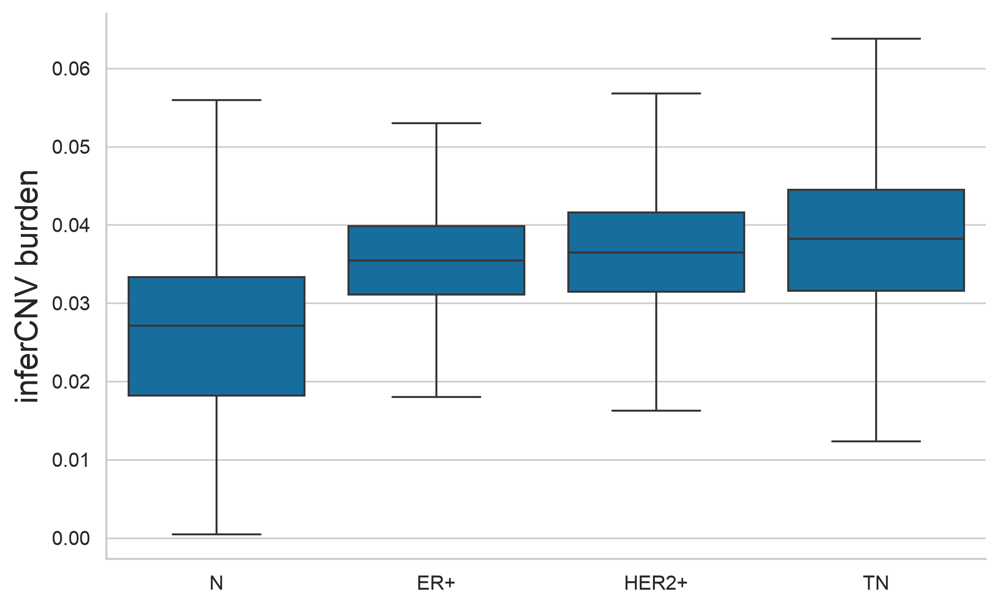

In [208]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=cnv_adata.obs,
    x="condition",
    y="cnv_score",
    order=["N", "ER+", "HER2+", "TN"],
    showfliers=False,
    ax=ax,
)

ax.set_xlabel("")


ax.set_ylabel("inferCNV burden")
sns.despine()

plt.savefig(fig_dir / "infercnv_score_by_condition.png", dpi=300, bbox_inches="tight")
plt.show()


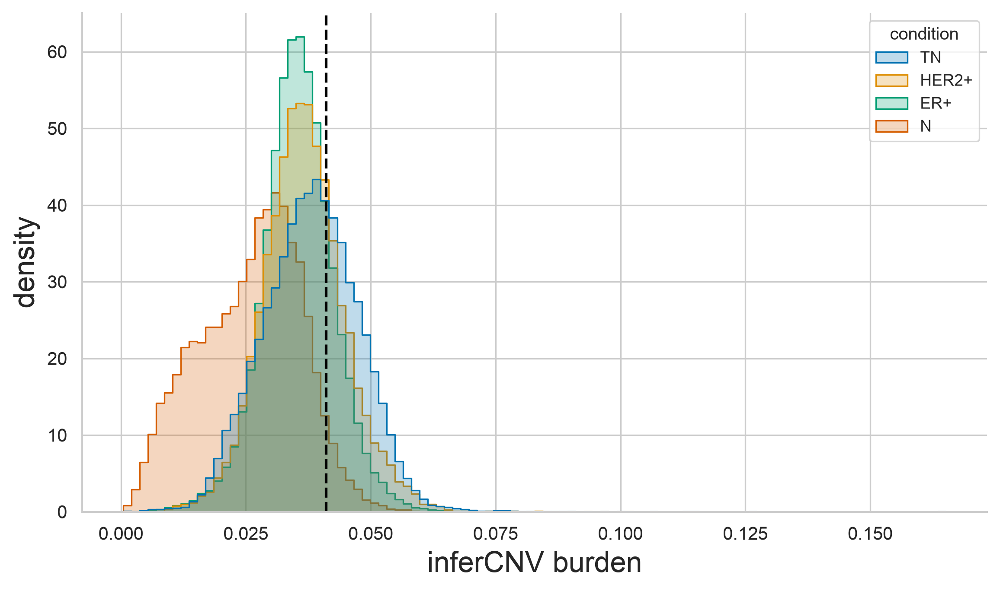

In [209]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=cnv_adata.obs,
    x="cnv_score",
    hue="condition",
    bins=100,
    stat="density",
    common_norm=False,
    element="step",
    ax=ax,
)


ax.axvline(cnv_high_threshold, linestyle="--", linewidth=1.5, color="black")
ax.set_xlabel("inferCNV burden")
ax.set_ylabel("density")
sns.despine()

plt.savefig(fig_dir / "infercnv_cnv_high_threshold.png", dpi=300, bbox_inches="tight")
plt.show()


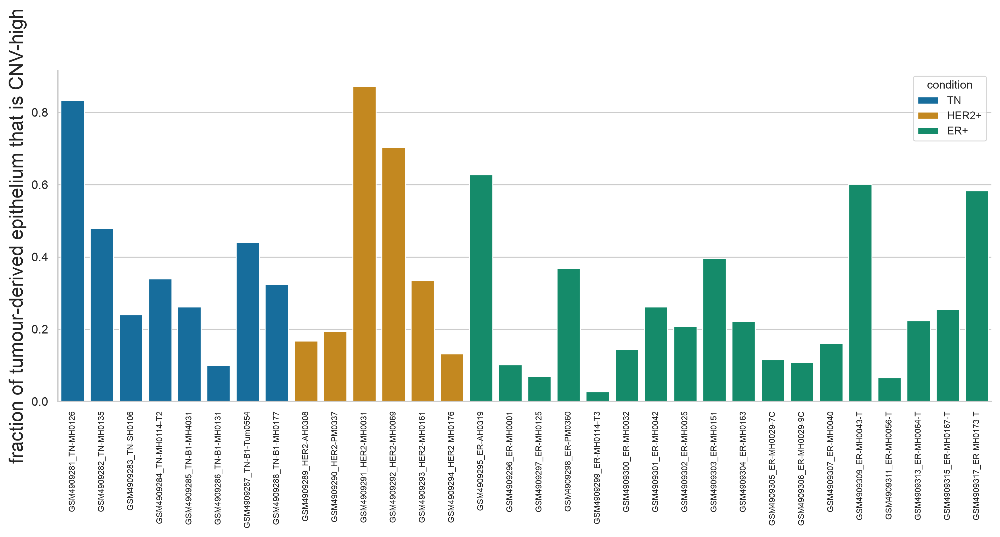

In [210]:
plot_data = sample_population_summary[
    sample_population_summary["condition"].ne("N")
].copy()

fig, ax = plt.subplots(figsize=(14, 5))


sns.barplot(
    data=plot_data,
    x="sample",
    y="tumour_derived_cnv_high_fraction",
    hue="condition",
    dodge=False,
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("fraction of tumour-derived epithelium that is CNV-high")
ax.tick_params(axis="x", rotation=90, labelsize=7)


sns.despine()

plt.savefig(
    fig_dir / "tumour_derived_cnv_high_fraction_by_sample.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


In [91]:
# transfer the inferCNV results onto the master object
assert epi.obs_names.equals(cnv_adata.obs_names)


In [92]:
transfer_columns = [
    "cnv_score", "cnv_signal", "tumour_derived", "cnv_high",
    "tumour_derived_cnv_high", "g1_cell", "tumour_derived_cnv_high_g1",
    "specimen_origin", "source_tumour_cluster",
    "source_tumour_cluster_eligible", "source_tumour_cluster_call",
]

for column in transfer_columns:
    epi.obs[column] = cnv_adata.obs[column].reindex(epi.obs_names)


In [93]:
boolean_columns = [
    "tumour_derived", "cnv_high", "tumour_derived_cnv_high", "g1_cell",
    "tumour_derived_cnv_high_g1", "source_tumour_cluster",
    "source_tumour_cluster_eligible",
]
for column in boolean_columns:
    epi.obs[column] = epi.obs[column].astype(bool)

epi.obs["specimen_origin"] = pd.Categorical(
    epi.obs["specimen_origin"], categories=origin_order
)
epi.obs["source_tumour_cluster_call"] = pd.Categorical(
    epi.obs["source_tumour_cluster_call"], categories=source_call_order
)


In [94]:
epi.uns["epithelial_population_definitions"] = {
    "primary_population": "specimen origin",
    "tumour_derived": "epithelial cells from ER+, HER2+ or TN specimens",
    "normal_tissue": "epithelial cells from normal specimens",
    "tumour_derived_cnv_high": "tumour-derived and CNV burden above normal q95",
    "tumour_derived_cnv_high_limitation": (
        "conservative CNV-enriched subgroup; does not classify all tumour-derived cells"
    ),
    "cnv_method": "infercnvpy",
    "cnv_reference": "normal epithelial cells; leave-one-sample-out for normal samples",
    "gene_annotation": "GENCODE v50 joined by Ensembl gene ID",
    "expression_layer": "log-normalised expression",
    "window_size": 100,
    "step": 10,
    "dynamic_threshold": float(infercnv_dynamic_threshold),
    "cnv_score": "chromosome-level RMS burden weighted by window count",
    "cnv_high_normal_quantile": float(cnv_high_quantile),
    "cnv_high_threshold": cnv_high_threshold,
    "cnv_high_threshold_g1_reference": cnv_high_threshold_g1,
    "source_cluster_file": source_tumour_file.name,
    "source_cluster_rows": int(len(source_tumour)),
    "cnv_score_vs_total_counts_r": float(r),
}


In [95]:
pd.DataFrame({
    "tumour_derived": [int(epi.obs["tumour_derived"].sum())],
    "normal_tissue": [int((~epi.obs["tumour_derived"]).sum())],
    "cnv_high_all_epithelium": [int(epi.obs["cnv_high"].sum())],
    "tumour_derived_cnv_high": [int(epi.obs["tumour_derived_cnv_high"].sum())],
    "tumour_derived_cnv_high_g1": [int(epi.obs["tumour_derived_cnv_high_g1"].sum())],
    "source_tumour_clusters": [int(epi.obs["source_tumour_cluster"].sum())],
})


,tumour_derived,normal_tissue,cnv_high_all_epithelium,tumour_derived_cnv_high,tumour_derived_cnv_high_g1,source_tumour_clusters
0,103174,26425,27679,26357,13555,70710


In [96]:
cnv_adata.obsm["X_cnv"] = x_cnv_full


In [97]:
cnv_adata.write_h5ad(save_dir / "epithelial_infercnv.h5ad", compression="gzip")


In [98]:
del cnv_adata, reference, x_cnv_full
gc.collect()


612

## scVI integration

In [99]:
epi_scvi = epi[:, epi.var["highly_variable"]].copy()


In [100]:
assert epi_scvi.n_obs == epi.n_obs
assert epi_scvi.n_vars == n_hvg_deviance


In [101]:
epi_scvi.shape


(129599, 4000)

In [102]:
# sample (library) identity is the batch covariate
scvi.model.SCVI.setup_anndata(epi_scvi, layer="counts", batch_key="sample")


In [103]:
model = scvi.model.SCVI(
    epi_scvi,
    n_latent=n_latent,
    n_layers=n_layers,
    gene_likelihood=gene_likelihood,
)


In [104]:
# free the large intermediates; nothing below uses them
del epi_scvi
gc.collect()


152

In [105]:
model


SCVI model with the following parameters: 
n_hidden: 128, n_latent: 20, n_layers: 2, dropout_rate: 0.1, dispersion: gene, gene_likelihood: nb, 
latent_distribution: normal.
Training status: Not Trained
Model's adata is minified?: False

In [106]:
# min_delta of 1.0 nat on the ELBO stops training once the remaining gain is small relative to the reconstruction term; it sets the epoch count reported
model.train(
    max_epochs=400,
    accelerator="mps",
    batch_size=1024,
    early_stopping=True,
    early_stopping_patience=20,
    early_stopping_min_delta=1.0,
)


/opt/miniconda3/envs/cap/lib/python3.11/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/miniconda3/envs/cap/

Epoch 206/400:  52%|█████▏    | 206/400 [21:12<19:58,  6.18s/it, v_num=1, train_loss=2.78e+3]
Monitored metric elbo_validation did not improve in the last 20 records. Best score: 2796.689. Signaling Trainer to stop.


In [107]:
n_epochs = model.history["elbo_train"].shape[0]


In [108]:
n_epochs


206

In [109]:
model.save(str(model_dir), overwrite=True)
model.history["elbo_train"].to_csv(df_dir / "scvi_epithelial_history.csv")


In [110]:
latent = model.get_latent_representation()


In [111]:
assert latent.shape == (epi.n_obs, 20)
assert np.isfinite(latent).all()


In [112]:
epi.obsm["X_scVI"] = latent


In [113]:
latent.shape


(129599, 20)

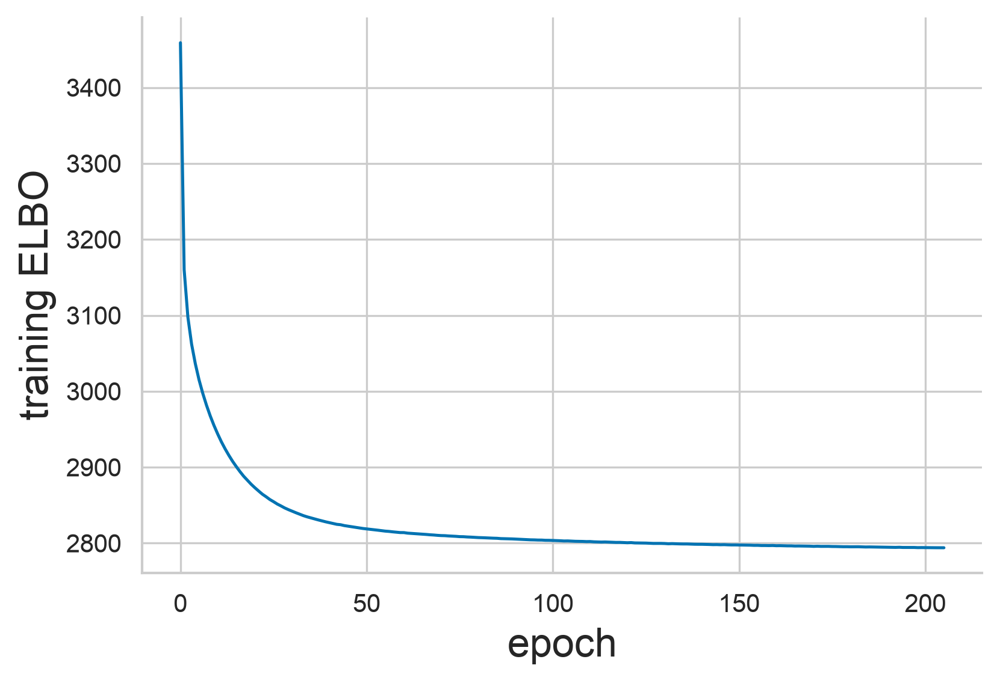

In [211]:
fig, ax = plt.subplots(figsize=(6, 4))

training_history = pd.read_csv(df_dir / "scvi_epithelial_history.csv", index_col=0)
training_history.plot(ax=ax, legend=False)

ax.set_xlabel("epoch")
ax.set_ylabel("training ELBO")
sns.despine()

plt.savefig(fig_dir / "scvi_epithelial_elbo.png", dpi=300, bbox_inches="tight")
plt.show()


## Neighbours, UMAP and Leiden clustering

In [115]:
sc.pp.neighbors(
    epi,
    use_rep="X_scVI",
    n_neighbors=n_neighbors,
    random_state=random_seed,
)
sc.tl.umap(epi, random_state=random_seed)


computing neighbors
    finished (0:00:19)
computing UMAP
    finished (0:00:50)


In [116]:
from sklearn.metrics import adjusted_rand_score


In [117]:
leiden_summary = []


In [118]:
for resolution in leiden_resolutions:
    key = f"leiden_r{resolution:g}"
    sc.tl.leiden(
        epi,
        resolution=resolution,
        key_added=key,
        flavor="igraph",
        n_iterations=2,
        directed=False,
        random_state=random_seed,
    )
    leiden_summary.append({"resolution": resolution, "n_clusters": epi.obs[key].nunique()})


running Leiden clustering
    finished (0:00:04)
running Leiden clustering
    finished (0:00:04)
running Leiden clustering
    finished (0:00:05)
running Leiden clustering
    finished (0:00:05)


In [119]:
display(pd.DataFrame(leiden_summary))


,resolution,n_clusters
0,0.5,13
1,1.0,21
2,1.2,26
3,1.5,32


In [120]:
primary_key = f"leiden_r{primary_resolution:g}"
resolution_stability = pd.DataFrame({
    "resolution": leiden_resolutions,
    "ari_vs_primary": [
        adjusted_rand_score(epi.obs[primary_key], epi.obs[f"leiden_r{resolution:g}"])
        for resolution in leiden_resolutions
    ],
})
display(resolution_stability.round(3))


,resolution,ari_vs_primary
0,0.5,1.000
1,1.0,0.390
2,1.2,0.303
3,1.5,0.267


In [121]:
epi.obs["epi_leiden"] = epi.obs[primary_key].copy()


In [122]:
epi.obs["epi_leiden"].value_counts().sort_index()


epi_leiden
0     10458
1       154
2     51915
3     16896
4      6161
5     17153
6      5968
7      1402
8      3246
9      5876
10     2097
11     8081
12      192
Name: count, dtype: int64

## Integration diagnostics

In [123]:
from sklearn.metrics import silhouette_score


In [124]:
rng = np.random.default_rng(0)

n_eval = min(20000, epi.n_obs)
eval_idx = rng.choice(epi.n_obs, size=n_eval, replace=False)

z_eval = epi.obsm["X_scVI"][eval_idx]
obs_eval = epi.obs.iloc[eval_idx]

bio_asw = silhouette_score(z_eval, obs_eval["cl_annotation"], metric="euclidean")
batch_asw = silhouette_score(z_eval, obs_eval["sample"], metric="euclidean")

print(f"annotation silhouette: {bio_asw:.3f}")


annotation silhouette: 0.039


In [125]:
print(f"sample silhouette:     {batch_asw:.3f}")


sample silhouette:     -0.070


In [126]:
pd.DataFrame({
    "metric": ["annotation_silhouette", "sample_silhouette"],
    "value": [bio_asw, batch_asw],
}).to_csv(df_dir / "scvi_epithelial_integration_metrics.csv", index=False)


In [127]:
cluster_composition = pd.crosstab(
    epi.obs["epi_leiden"], epi.obs["sample"], normalize="index"
)
cluster_composition["top_sample_fraction"] = cluster_composition.max(axis=1)
cluster_composition.to_csv(df_dir / "scvi_epithelial_cluster_sample_composition.csv")
display(cluster_composition.sort_values("top_sample_fraction", ascending=False).round(3))


sample,GSM4909253_N-PM0092-Total,GSM4909254_N-PM0019-Total,GSM4909257_N-PM0095-Total,GSM4909261_N-PM0230-Total,GSM4909263_N-MH0064-Total,GSM4909265_N-PM0233-Total,GSM4909266_N-MH0169-Total,GSM4909268_N-MH0023-Total,GSM4909270_N-PM0342-Total,GSM4909271_N-MH288-Total,...,GSM4909304_ER-MH0163,GSM4909305_ER-MH0029-7C,GSM4909306_ER-MH0029-9C,GSM4909307_ER-MH0040,GSM4909309_ER-MH0043-T,GSM4909311_ER-MH0056-T,GSM4909313_ER-MH0064-T,GSM4909315_ER-MH0167-T,GSM4909317_ER-MH0173-T,top_sample_fraction
epi_leiden,,,,,,,,,,,,,,,,,,,,,
12,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.979,0.000,0.000,0.000,0.000,0.000,0.000,0.979
1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.006,0.000,...,0.000,0.006,0.000,0.013,0.000,0.000,0.000,0.000,0.000,0.604
10,0.015,0.052,0.002,0.003,0.000,0.050,0.001,0.002,0.003,0.000,...,0.001,0.006,0.004,0.001,0.067,0.003,0.022,0.000,0.090,0.403
9,0.004,0.011,0.001,0.002,0.000,0.034,0.004,0.009,0.003,0.000,...,0.000,0.019,0.020,0.003,0.007,0.000,0.191,0.000,0.016,0.392
3,0.003,0.003,0.003,0.000,0.000,0.001,0.000,0.003,0.001,0.000,...,0.054,0.005,0.018,0.032,0.039,0.005,0.003,0.046,0.021,0.343
4,0.059,0.034,0.021,0.017,0.044,0.073,0.018,0.310,0.086,0.016,...,0.005,0.004,0.007,0.004,0.005,0.002,0.001,0.010,0.002,0.310
11,0.122,0.226,0.038,0.054,0.004,0.082,0.027,0.075,0.309,0.003,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.001,0.000,0.309
0,0.001,0.001,0.001,0.000,0.000,0.001,0.000,0.000,0.001,0.000,...,0.017,0.005,0.002,0.003,0.000,0.003,0.001,0.007,0.001,0.297
6,0.002,0.000,0.038,0.002,0.001,0.008,0.009,0.002,0.003,0.000,...,0.022,0.000,0.001,0.001,0.002,0.001,0.000,0.228,0.006,0.280


In [128]:
cluster_composition.to_csv(df_dir / "scvi_epithelial_cluster_sample_composition.csv")


In [129]:
cluster_population = (
    epi.obs
    .groupby("epi_leiden", observed=True)
    .agg(
        n_cells=("tumour_derived", "size"),
        n_tumour_derived=("tumour_derived", "sum"),
        n_tumour_derived_cnv_high=("tumour_derived_cnv_high", "sum"),
        n_tumour_derived_cnv_high_g1=("tumour_derived_cnv_high_g1", "sum"),
        median_cnv=("cnv_score", "median"),
    )
)


In [130]:
cluster_population["tumour_derived_fraction"] = (
    cluster_population["n_tumour_derived"] / cluster_population["n_cells"]
)
cluster_population["tumour_derived_cnv_high_fraction"] = (
    cluster_population["n_tumour_derived_cnv_high"] / cluster_population["n_cells"]
)


In [131]:
cluster_population.sort_values(
    "tumour_derived_cnv_high_fraction", ascending=False
).round(3)


,n_cells,n_tumour_derived,n_tumour_derived_cnv_high,n_tumour_derived_cnv_high_g1,median_cnv,tumour_derived_fraction,tumour_derived_cnv_high_fraction
epi_leiden,,,,,,,
1,154,153,99,83,0.043,0.994,0.643
3,16896,16641,8240,392,0.041,0.985,0.488
0,10458,10402,2861,1964,0.036,0.995,0.274
2,51915,51277,11699,8850,0.036,0.988,0.225
7,1402,670,193,130,0.033,0.478,0.138
5,17153,7142,2201,1539,0.026,0.416,0.128
6,5968,5563,488,217,0.031,0.932,0.082
9,5876,5454,268,153,0.032,0.928,0.046
4,6161,514,125,102,0.030,0.083,0.020


In [132]:
cluster_population.to_csv(
    df_dir / "scvi_epithelial_cluster_population_composition.csv"
)


In [133]:
# canonical epithelial markers, to confirm the clusters are epithelial
marker_genes = [
    g for g in ["EPCAM", "KRT8", "KRT18", "KRT19", "KRT7", "KRT5", "KRT14", "KRT17", "MUC1"]
    if g in epi.var_names
]


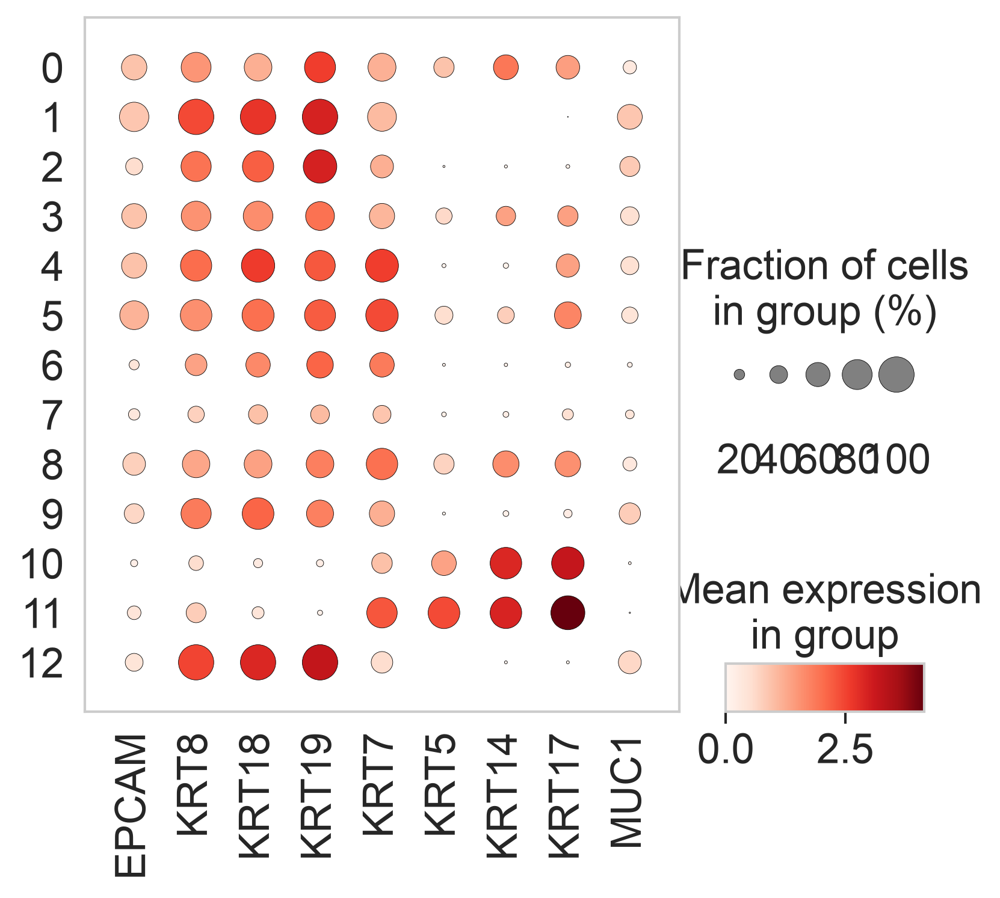

In [212]:
sc.pl.dotplot(
    epi,
    var_names=marker_genes,
    groupby="epi_leiden",
    layer="lognorm",
    use_raw=False,
    figsize=(6, 5),
    show=False,
)

plt.savefig(fig_dir / "epithelial_cluster_markers_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()


## Figure 1a and related UMAPs

In [135]:
condition_palette = {
    "N": "#031A6B",
    "ER+": "#F46036",
    "HER2+": "#2CA02C",
    "TN": "#976391",
}


In [136]:
condition_order = ["TN", "HER2+", "ER+", "N"]


In [137]:
epi.obs["condition"] = pd.Categorical(
    epi.obs["condition"].astype(str), categories=condition_order, ordered=True
)


In [138]:
# set the colours on the object, so plotting a subset does not have to write them
epi.uns["condition_colors"] = [condition_palette[c] for c in condition_order]


In [139]:
epi.obs["cl_annotation"] = epi.obs["cl_annotation"].astype("category")


In [140]:
epi.obs["sample_short"] = (
    epi.obs["sample_short"].astype("category").cat.remove_unused_categories()
)


In [141]:
# draw N first so that the tumour conditions are not hidden underneath it
draw_order = ["N", "TN", "HER2+", "ER+"]
rank = {condition: i for i, condition in enumerate(draw_order)}

plot_idx = epi.obs["condition"].astype(str).map(rank).sort_values().index


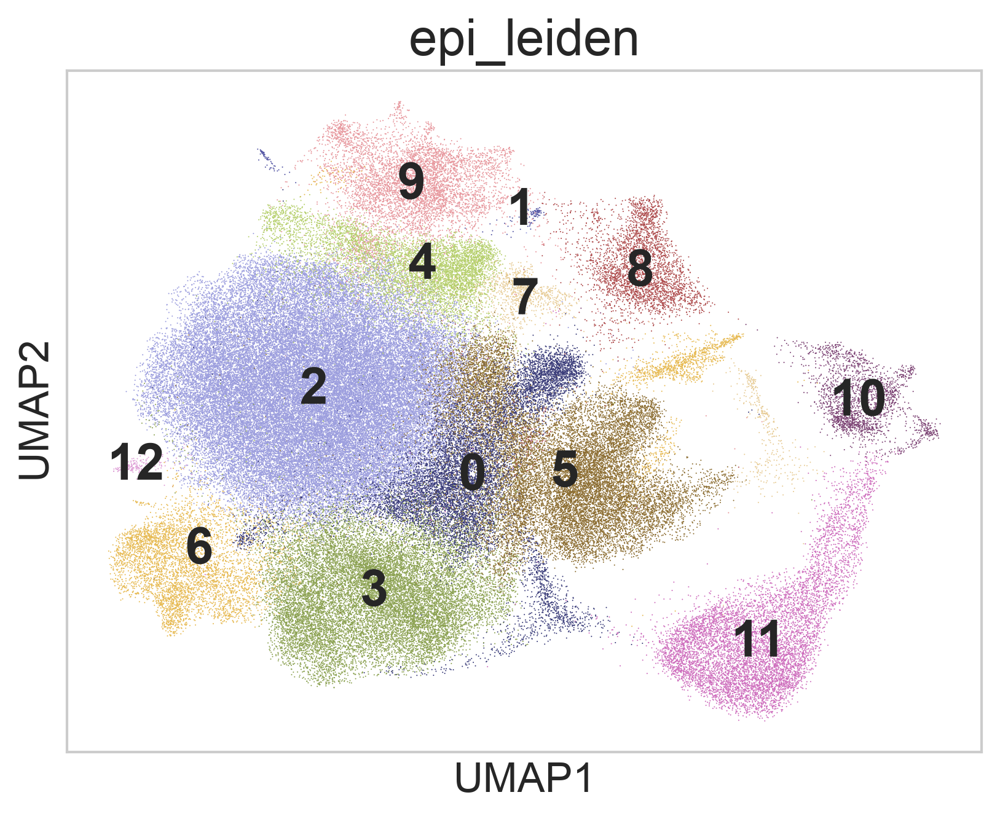

In [142]:
sc.pl.umap(epi, color="epi_leiden", palette="tab20b",legend_loc="on data",)


/opt/miniconda3/envs/cap/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


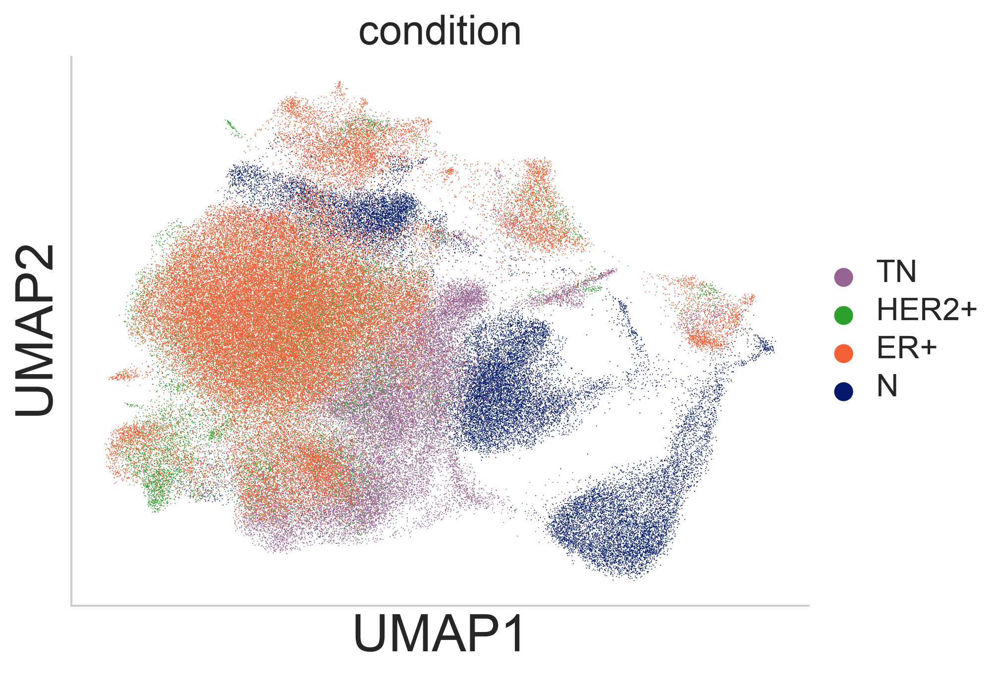

In [213]:
sc.pl.umap(
    epi[plot_idx],
    color="condition",
    palette=condition_palette,
    frameon=True,
    show=False,
)

ax = plt.gca()
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)


ax.tick_params(axis="both", labelsize=12)

legend = ax.get_legend()


if legend is not None:
    plt.setp(legend.get_texts(), fontsize=15)
    for handle in legend.legend_handles:
        handle.set_sizes([70])


plt.savefig(fig_dir / "epithelial_umap_condition.png", dpi=300, bbox_inches="tight")
plt.show()


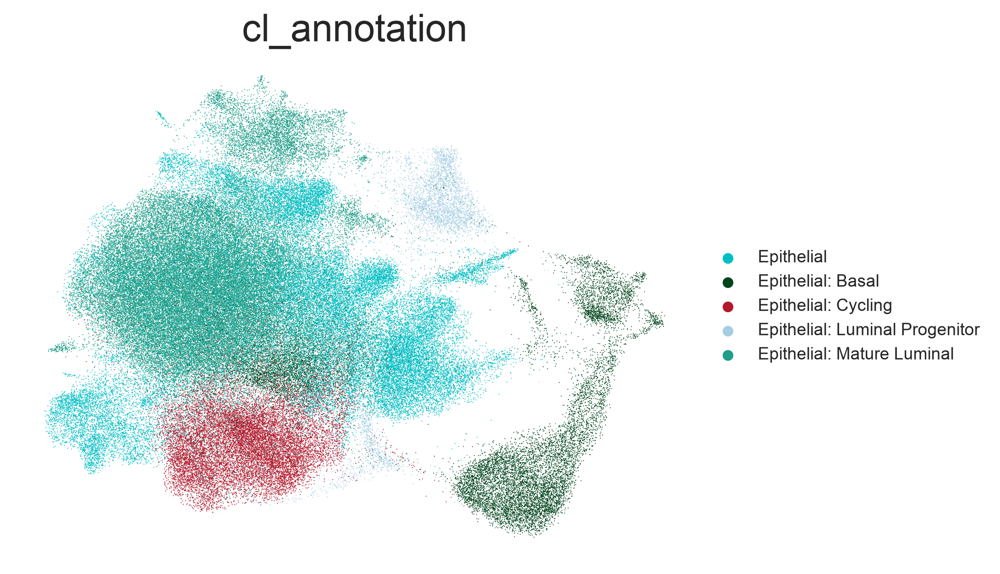

In [214]:
sc.pl.umap(epi, color="cl_annotation", frameon=False, show=False)

plt.savefig(fig_dir / "epithelial_umap_cl_annotation.png", dpi=300, bbox_inches="tight")
plt.show()


In [148]:
# Exploratory marker ranking for epithelial clusters.
sc.tl.rank_genes_groups(
    epi,
    groupby="epi_leiden",
    layer="lognorm",
    use_raw=False,
    method="wilcoxon",
    pts=True,
    tie_correct=True,
)


ranking genes
    finished (0:06:09)


In [149]:
cluster_markers = sc.get.rank_genes_groups_df(
    epi,
    group=None,
)

cluster_markers.to_csv(
    df_dir / "epithelial_cluster_markers_wilcoxon.csv",
    index=False,
)


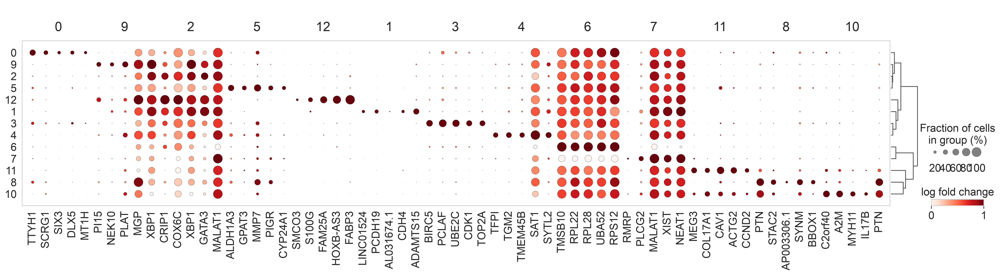

In [215]:
sc.pl.rank_genes_groups_dotplot(
    epi,
    groupby="epi_leiden",
    n_genes=5,
    values_to_plot="logfoldchanges",
    standard_scale="var",
    show=False,
)


plt.savefig(
    fig_dir / "epithelial_cluster_markers_top5.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


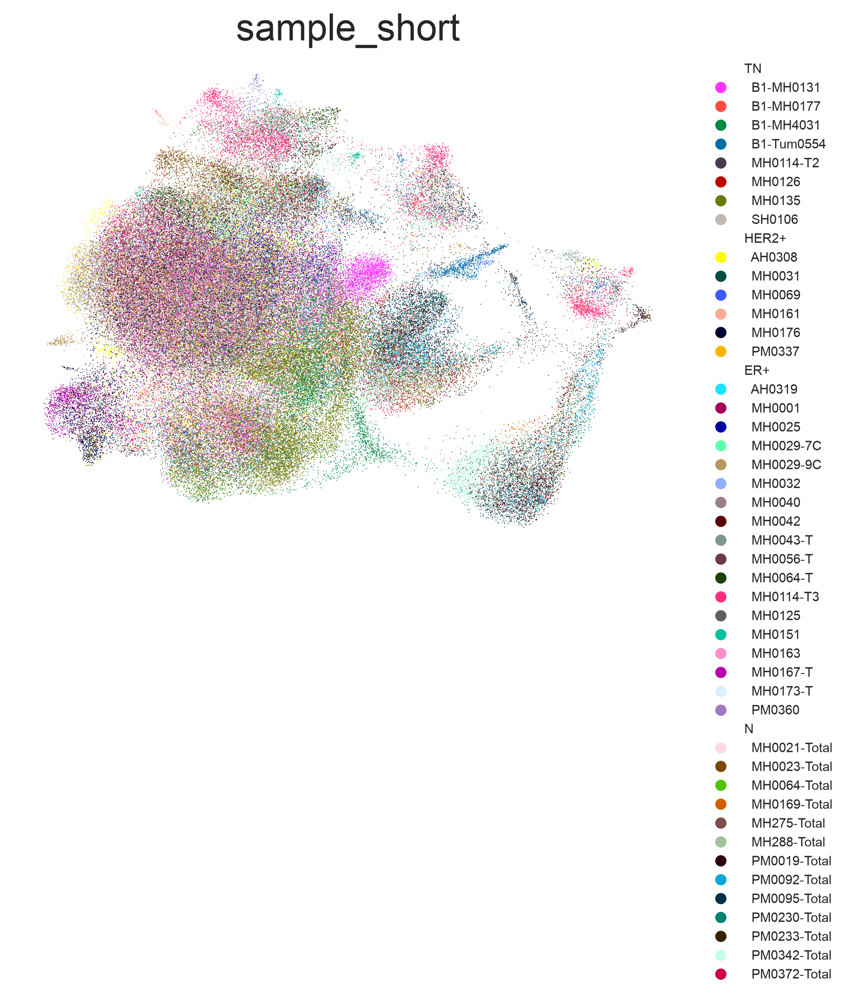

In [216]:
# samples coloured individually, with the legend grouped by condition


sc.pl.umap(epi, color="sample_short", legend_loc=None, frameon=False, show=False)

ax = plt.gca()

# read the colours scanpy just assigned, so the legend matches the plot
sample_to_color = dict(
    zip(epi.obs["sample_short"].cat.categories, epi.uns["sample_short_colors"])
)

handles = []


for condition in condition_order:

    handles.append(Line2D([], [], linestyle="none", label=condition, color="black"))

    for sample in sorted(epi.obs.loc[epi.obs["condition"] == condition, "sample_short"].unique()):
        handles.append(
            Line2D([], [], marker="o", linestyle="none", markersize=6,
                   markerfacecolor=sample_to_color[sample], markeredgecolor="none",
                   label=f"  {sample}")
        )


ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=7)

plt.savefig(fig_dir / "epithelial_umap_sample.png", dpi=300, bbox_inches="tight")
plt.show()


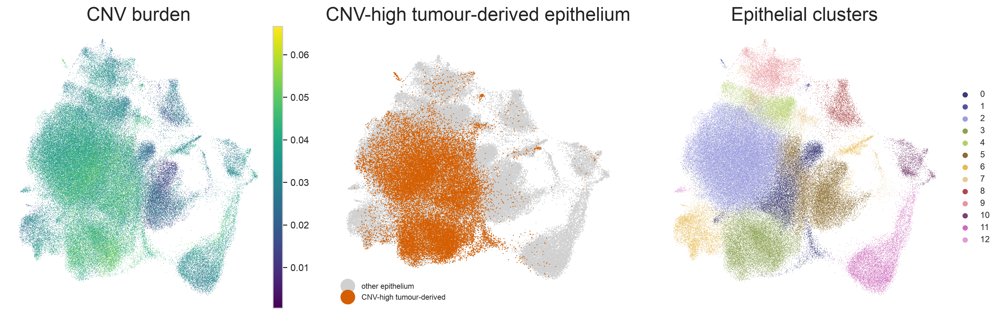

In [217]:
umap = epi.obsm["X_umap"]
tumour_derived_cnv_high_plot = epi.obs["tumour_derived_cnv_high"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sc.pl.umap(
    epi, color="cnv_score", color_map="viridis", vmax="p99.9",
    frameon=False, title="CNV burden", ax=axes[0], show=False,
)


axes[1].scatter(
    umap[:, 0], umap[:, 1], s=1, color="#D0D0D0",
    linewidths=0, rasterized=True,
)
axes[1].scatter(
    umap[tumour_derived_cnv_high_plot, 0], umap[tumour_derived_cnv_high_plot, 1], s=1, color="#D55E00",
    linewidths=0, rasterized=True,
)
axes[1].set_title("CNV-high tumour-derived epithelium")
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].set_aspect("equal", adjustable="datalim")


axes[1].set_frame_on(False)
axes[1].legend(
    handles=[
        Line2D([], [], marker="o", linestyle="none", color="#D0D0D0", label="other epithelium"),
        Line2D([], [], marker="o", linestyle="none", color="#D55E00", label="CNV-high tumour-derived"),
    ],
    frameon=False, loc="lower left", markerscale=3, fontsize=8,
)


sc.pl.umap(
    epi, color="epi_leiden", legend_loc="right margin",
    frameon=False, title="Epithelial clusters", ax=axes[2], show=False,
)

fig.tight_layout()
fig.savefig(
    fig_dir / "epithelial_umap_population_and_cnv.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


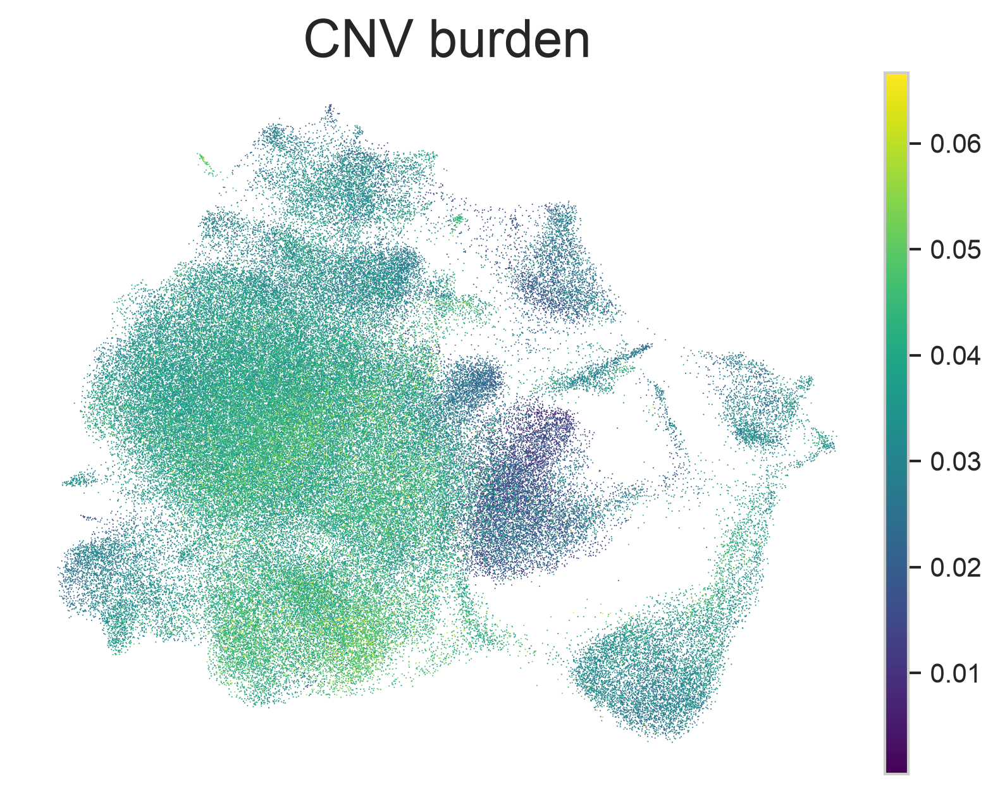

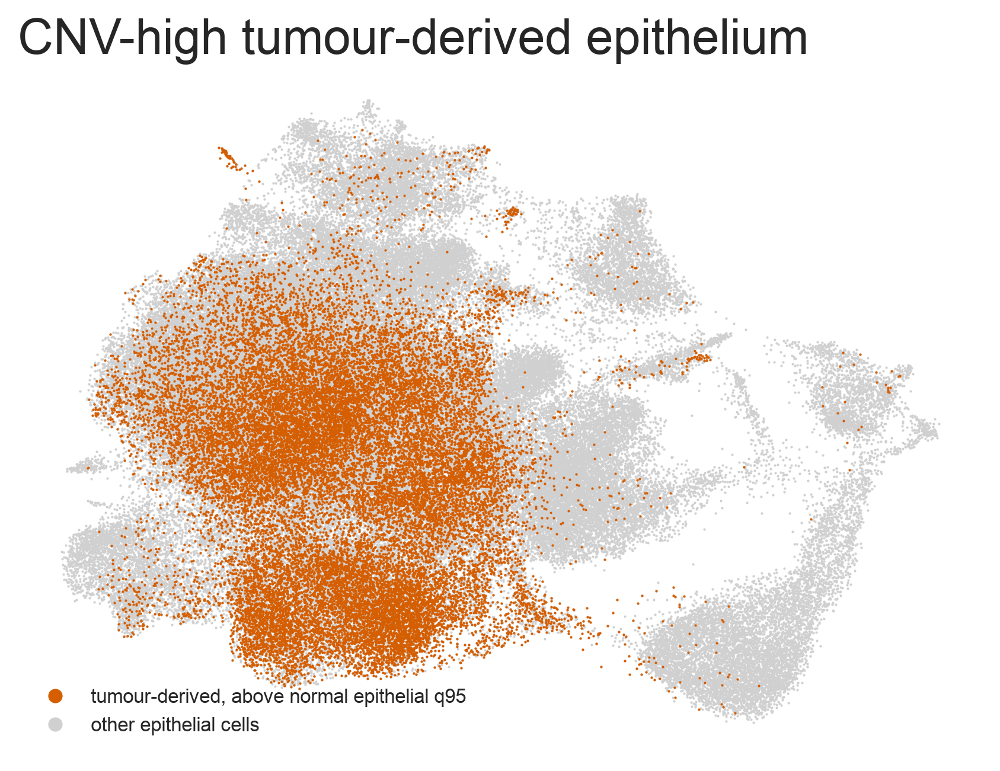

In [218]:
import sys
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))
from scripts.publication_figure_state import save_cnv_panels

save_cnv_panels(epi, fig_dir)

<Axes: title={'center': 'cnv_score'}, xlabel='UMAP1', ylabel='UMAP2'>

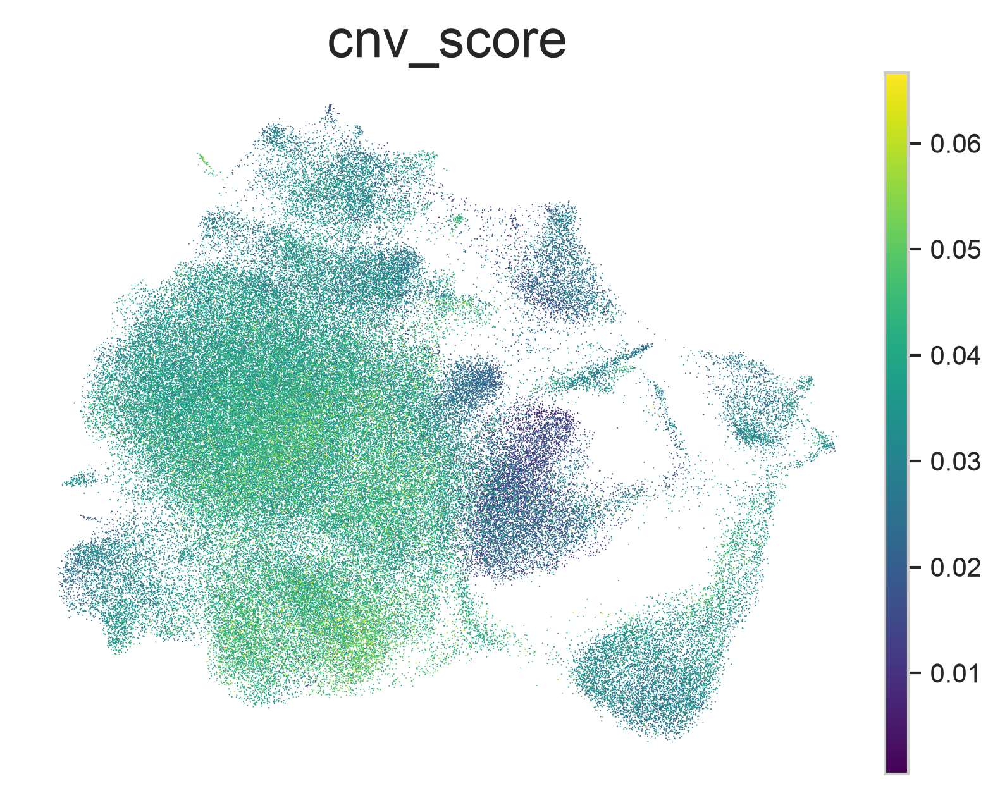

In [160]:
sc.pl.umap(epi, color='cnv_score', color_map='viridis', frameon=False, show=False, vmax='p99.9')


<Axes: title={'center': 'cnv_score'}, xlabel='UMAP1', ylabel='UMAP2'>

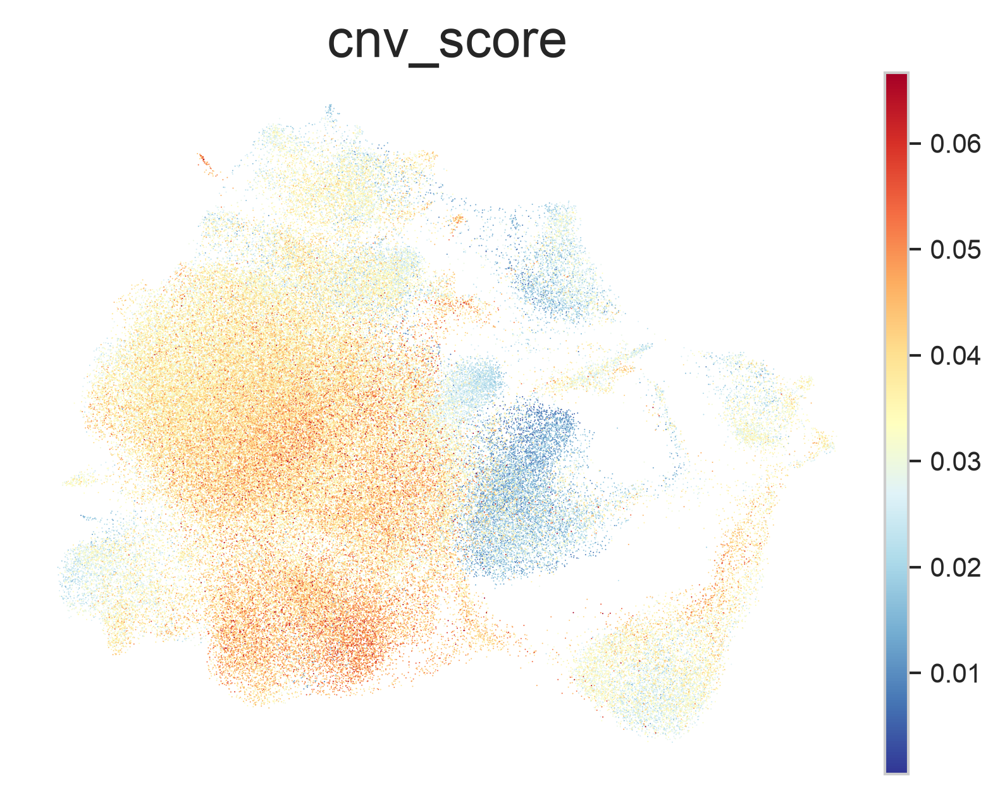

In [161]:
sc.pl.umap(epi, color='cnv_score', color_map='RdYlBu_r', frameon=False, show=False, vmax='p99.9')


In [162]:
origin_palette = {
    "normal-tissue epithelium": "#56B4E9",
    "tumour-derived epithelium": "#D55E00",
}


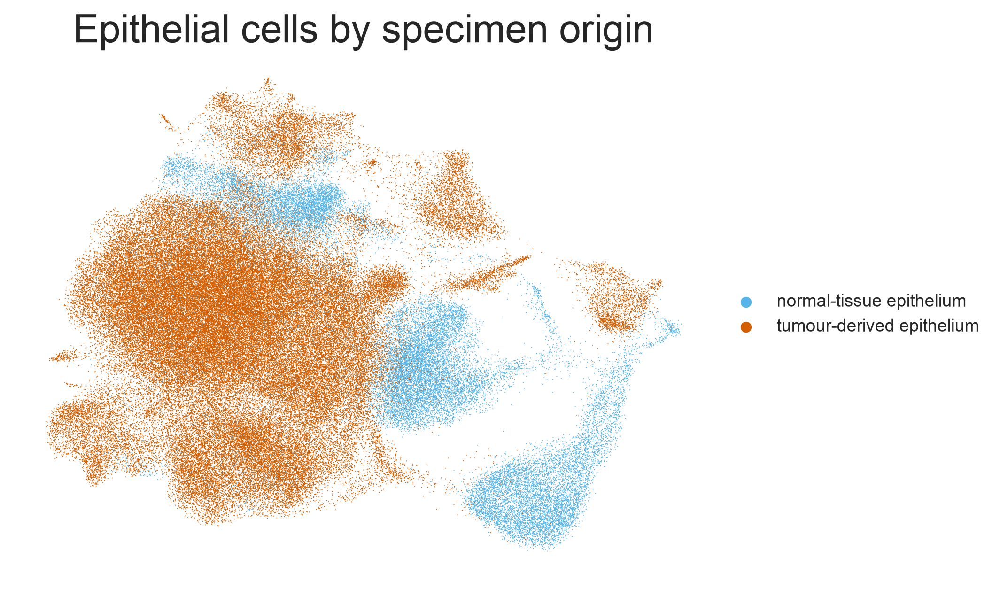

In [219]:
sc.pl.umap(
    epi,
    color="specimen_origin",
    palette=origin_palette,
    frameon=False,
    show=False,
    title="Epithelial cells by specimen origin",
)
plt.savefig(
    fig_dir / "epithelial_umap_specimen_origin.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## Feature-set sensitivity


The primary scVI model uses only the deviance-ranked genes. A second model adds
the antigen and meta-programme genes to test whether that targeted feature choice changes
the neighbourhood or cluster structure beyond ordinary run-to-run variation.


In [164]:
epi_protected = epi[:, epi.var["highly_variable_protected"]].copy()
assert epi_protected.n_vars == n_hvg_protected


In [165]:
scvi.model.SCVI.setup_anndata(
    epi_protected, layer="counts", batch_key="sample"
)


In [166]:
model_protected = scvi.model.SCVI(
    epi_protected,
    n_latent=n_latent,
    n_layers=n_layers,
    gene_likelihood=gene_likelihood,
)


In [167]:
model_protected.train(
    max_epochs=400,
    accelerator="mps",
    batch_size=1024,
    early_stopping=True,
    early_stopping_patience=20,
    early_stopping_min_delta=1.0,
)


/opt/miniconda3/envs/cap/lib/python3.11/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/miniconda3/envs/cap/

Epoch 187/400:  47%|████▋     | 187/400 [25:31<29:04,  8.19s/it, v_num=1, train_loss=2.89e+3]  
Monitored metric elbo_validation did not improve in the last 20 records. Best score: 2906.078. Signaling Trainer to stop.


In [168]:
epi.obsm["X_scVI_protected"] = model_protected.get_latent_representation()


In [169]:
del model_protected
gc.collect()


5267

In [170]:
sc.pp.neighbors(
    epi,
    use_rep="X_scVI_protected",
    n_neighbors=n_neighbors,
    random_state=random_seed,
    key_added="protected_neighbors",
)


computing neighbors
    finished (0:00:07)


In [171]:
sc.tl.leiden(
    epi,
    resolution=primary_resolution,
    key_added="epi_leiden_protected",
    neighbors_key="protected_neighbors",
    flavor="igraph",
    n_iterations=2,
    directed=False,
    random_state=random_seed,
)

del epi_protected


running Leiden clustering
    finished (0:00:05)


In [172]:
gc.collect()


782

In [173]:
epi_seed = epi[:, epi.var["highly_variable"]].copy()
scvi.settings.seed = random_seed + 1
scvi.model.SCVI.setup_anndata(epi_seed, layer="counts", batch_key="sample")
 


Seed set to 1


In [174]:
model_seed = scvi.model.SCVI(
    epi_seed,
    n_latent=n_latent,
    n_layers=n_layers,
    gene_likelihood=gene_likelihood,
)


In [175]:
model_seed.train(
    max_epochs=400,
    accelerator="mps",
    batch_size=1024,
    early_stopping=True,
    early_stopping_patience=20,
    early_stopping_min_delta=1.0,
)

epi.obsm["X_scVI_seed2"] = model_seed.get_latent_representation()
scvi.settings.seed = random_seed


/opt/miniconda3/envs/cap/lib/python3.11/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/miniconda3/envs/cap/

Epoch 189/400:  47%|████▋     | 189/400 [22:03<24:37,  7.00s/it, v_num=1, train_loss=2.78e+3]  
Monitored metric elbo_validation did not improve in the last 20 records. Best score: 2791.759. Signaling Trainer to stop.


Seed set to 0


In [176]:
sc.pp.neighbors(
    epi,
    use_rep="X_scVI_seed2",
    n_neighbors=n_neighbors,
    random_state=random_seed,
    key_added="seed2_neighbors",
)


computing neighbors
    finished (0:00:07)


In [177]:
sc.tl.leiden(
    epi,
    resolution=primary_resolution,
    key_added="epi_leiden_seed2",
    neighbors_key="seed2_neighbors",
    flavor="igraph",
    n_iterations=2,
    directed=False,
    random_state=random_seed,
)

del epi_seed, model_seed


running Leiden clustering
    finished (0:00:05)


In [178]:
gc.collect()


3041

In [179]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors


In [180]:
k_overlap = n_neighbors
overlap_idx = eval_idx


In [181]:
def knn_indices(representation):
    values = epi.obsm[representation][overlap_idx]
    model_nn = NearestNeighbors(n_neighbors=k_overlap + 1).fit(values)
    return model_nn.kneighbors(values, return_distance=False)[:, 1:]


In [182]:
primary_neighbors = knn_indices("X_scVI")
comparisons = [
    ("protected feature set", "X_scVI_protected", "epi_leiden_protected"),
    ("different seed", "X_scVI_seed2", "epi_leiden_seed2"),
]

rows = []


In [183]:
for label, representation, clustering in comparisons:
    other_neighbors = knn_indices(representation)
    overlap = np.array([
        len(set(left) & set(right)) / k_overlap
        for left, right in zip(primary_neighbors, other_neighbors)
    ])
    rows.append({
        "comparison": label,
        "leiden_ari": adjusted_rand_score(epi.obs["epi_leiden"], epi.obs[clustering]),
        "leiden_nmi": normalized_mutual_info_score(epi.obs["epi_leiden"], epi.obs[clustering]),
        "knn_overlap_mean": overlap.mean(),
        "knn_overlap_median": np.median(overlap),
        "n_clusters": epi.obs[clustering].nunique(),
    })


In [184]:
latent_comparison = pd.DataFrame(rows)
latent_comparison.to_csv(df_dir / "scvi_latent_comparison.csv", index=False)
display(latent_comparison.round(3))


,comparison,leiden_ari,leiden_nmi,knn_overlap_mean,knn_overlap_median,n_clusters
0,protected feature set,0.600,0.665,0.404,0.4,16
1,different seed,0.714,0.703,0.408,0.4,16


In [185]:
rows = []


In [186]:
for label, representation in [
    ("primary_deviance", "X_scVI"),
    ("protected_sensitivity", "X_scVI_protected"),
    ("primary_second_seed", "X_scVI_seed2"),
]:
    values = epi.obsm[representation][eval_idx]
    rows.append({
        "model": label,
        "annotation_silhouette": silhouette_score(values, obs_eval["cl_annotation"]),
        "sample_silhouette": silhouette_score(values, obs_eval["sample"]),
        "condition_silhouette": silhouette_score(values, obs_eval["condition"].astype(str)),
    })


In [187]:
model_comparison = pd.DataFrame(rows)
display(model_comparison.round(3))


,model,annotation_silhouette,sample_silhouette,condition_silhouette
0,primary_deviance,0.039,-0.070,0.013
1,protected_sensitivity,0.039,-0.067,0.008
2,primary_second_seed,0.037,-0.070,0.013


In [188]:
# free the large intermediates; nothing below uses them
del model
gc.collect()


0

In [189]:
rows = []


In [190]:
for annotation in obs_eval["cl_annotation"].value_counts().index:
    mask = obs_eval["cl_annotation"].eq(annotation).to_numpy()
    if mask.sum() < 100 or obs_eval.loc[mask, "sample"].nunique() < 2:
        continue

    row = {"cl_annotation": annotation, "n_cells": int(mask.sum())}
    for label, representation in [
        ("primary_deviance", "X_scVI"),
        ("protected_sensitivity", "X_scVI_protected"),
        ("primary_second_seed", "X_scVI_seed2"),
    ]:
        row[label] = silhouette_score(
            epi.obsm[representation][eval_idx][mask],
            obs_eval.loc[mask, "sample"],
        )
    rows.append(row)


In [191]:
within_annotation = pd.DataFrame(rows)
display(within_annotation.round(3))


,cl_annotation,n_cells,primary_deviance,protected_sensitivity,primary_second_seed
0,Epithelial: Mature Luminal,8971,-0.062,-0.059,-0.057
1,Epithelial,5789,-0.079,-0.077,-0.072
2,Epithelial: Cycling,2562,-0.185,-0.155,-0.170
3,Epithelial: Basal,2036,-0.099,-0.094,-0.107
4,Epithelial: Luminal Progenitor,642,-0.050,-0.062,-0.052


In [192]:
cluster_overlap = pd.crosstab(
    epi.obs["epi_leiden"], epi.obs["epi_leiden_protected"]
)
best_match = cluster_overlap.max(axis=1) / cluster_overlap.sum(axis=1)

feature_effect = latent_comparison.iloc[0]
seed_floor = latent_comparison.iloc[1]


In [193]:
epi.uns["protected_gene_sensitivity"] = {
    "primary_features": int(n_hvg_deviance),
    "protected_features": int(n_hvg_protected),
    "protected_added": int(n_protected_added),
    "feature_set_ari": float(feature_effect["leiden_ari"]),
    "seed_floor_ari": float(seed_floor["leiden_ari"]),
    "feature_set_knn_overlap": float(feature_effect["knn_overlap_mean"]),
    "seed_floor_knn_overlap": float(seed_floor["knn_overlap_mean"]),
    "k": int(k_overlap),
}

model_comparison.to_csv(df_dir / "scvi_feature_sensitivity.csv", index=False)


In [194]:
within_annotation.to_csv(
    df_dir / "scvi_feature_sensitivity_by_annotation.csv", index=False
);


In [195]:
best_match.rename("largest_matching_fraction").to_csv(
    df_dir / "scvi_feature_cluster_correspondence.csv"
)


## Save

In [196]:
final_positive = {
    gene: int((np.asarray(epi[:, gene].layers["counts"].todense()).ravel() > 0).sum())
    for gene in target_genes
}

assert epi.n_obs == n_cells_start
assert epi.n_vars == n_genes_start
assert final_positive == {gene: baseline_positive[gene] for gene in final_positive}


In [197]:
epi.uns["epithelial_integration"] = {
    "hvg_method": "binomial deviance (scry), maximum across samples",
    "primary_feature_set": "deviance-ranked genes only",
    "n_hvg_primary": int(n_hvg_deviance),
    "n_hvg_protected_sensitivity": int(n_hvg_protected),
    "scvi_n_latent": int(n_latent),
    "scvi_n_layers": int(n_layers),
    "scvi_gene_likelihood": gene_likelihood,
    "scvi_batch_key": "sample",
    "scvi_epochs": int(n_epochs),
    "n_neighbors": int(n_neighbors),
    "leiden_resolutions": [float(value) for value in leiden_resolutions],
    "leiden_primary": float(primary_resolution),
    "seed": int(random_seed),
}


Source barcode transfer audit. Recovery after QC is reported separately from sample identity; ER-MH0001 is excluded from transfer. This is optional concordance, not the primary specimen-origin definition.

In [220]:
import sys
repository = find_publication()
if str(repository) not in sys.path:
    sys.path.insert(0, str(repository))
check_dir = repository / "results" / "publication_checks"
check_dir.mkdir(parents=True, exist_ok=True)

from scripts.publication_targeted_checks import barcode_audit

barcode_recovery = barcode_audit(epi, project, repository, check_dir)
barcode_recovery.loc[barcode_recovery["source_group_available"]]


,sample,condition,sample_code,source_group_available,n_source_barcodes,n_epithelial,source_in_epithelial,source_in_retained_qc,best_any_source_overlap,best_any_source_group,excluded_from_transfer,source_recovery_in_epithelium
13,GSM4909281_TN-MH0126,TN,0126,True,1235,1079,1060,1062,1060,"('TN', '0126')",False,0.858300
14,GSM4909282_TN-MH0135,TN,0135,True,14333,12274,12126,12145,12126,"('TN', '0135')",False,0.846020
15,GSM4909283_TN-SH0106,TN,0106,True,54,54,45,45,45,"('TN', '0106')",False,0.833333
16,GSM4909284_TN-MH0114-T2,TN,0114,True,177,156,126,130,126,"('TN', '0114')",False,0.711864
17,GSM4909285_TN-B1-MH4031,TN,4031,True,5129,4693,4613,4616,4613,"('TN', '4031')",False,0.899396
18,GSM4909286_TN-B1-MH0131,TN,0131,True,5513,4850,4753,4758,4753,"('TN', '0131')",False,0.862144
19,GSM4909287_TN-B1-Tum0554,TN,0554,True,2337,2684,1851,1858,1851,"('TN', '0554')",False,0.792041
20,GSM4909288_TN-B1-MH0177,TN,0177,True,1575,827,584,622,584,"('TN', '0177')",False,0.370794
21,GSM4909289_HER2-AH0308,HER2+,0308,True,3317,3029,2823,2824,2823,"('HER2+', '0308')",False,0.851070
22,GSM4909290_HER2-PM0337,HER2+,0337,True,3924,2943,2822,2826,2822,"('HER2+', '0337')",False,0.719164


In [198]:
out_path = save_dir / "epithelial_tumour_scvi.h5ad"


In [199]:
for name in list(epi.layers.keys()):
    if not sp.issparse(epi.layers[name]):
        epi.layers[name] = sp.csr_matrix(epi.layers[name])


In [200]:
if not sp.issparse(epi.X):
    epi.X = sp.csr_matrix(epi.X)


In [ ]:
if not epi.uns.get("figure_only", False):
    # Write safely before replacing the existing file.
    tmp_path = out_path.with_suffix(".h5ad.tmp")
    epi.write_h5ad(tmp_path, compression="gzip")
    os.replace(tmp_path, out_path)

    display(pd.DataFrame({"saved": [out_path.name]}))

In [202]:
check = sc.read_h5ad(out_path, backed="r")

assert check.n_obs == epi.n_obs
assert check.n_vars == epi.n_vars


In [203]:
check.shape


(129599, 27357)

In [204]:
del check
gc.collect()


1300

In [205]:
import session_info


In [206]:
session_info.show()


/opt/miniconda3/envs/cap/lib/python3.11/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  mod_version = _find_version(mod.__version__)
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  mod_version = _find_version(mod.__version__)
